# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`ransformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?

Словник стане менш точним, хоча код продовжуватиме працювати.

Ітератор з окремих віршів розглядає кожен вірш як незалежний документ, тому BPE не злиає символи через межі віршів. Якщо склеїти вірші в один рядок, на стику з'являться хибні пари і вони будуть потрапляти у словник з великою частотою.

2. З який етапів складається токенізація, поясніть сутність кожного з етапів


Нормалізація (Normalization) - етап підготовки тексту до обробки. Очищення тексту та приведення символів до єдиного формату (видалення зайвих пробілів, нормалізацію Unicode-символів ...).

Попередня токенізація (Pre-tokenization) - текст розбивається на слова або інші початкові одиниці відповідно до визначених правил.

Токенізація моделлю (Tokenization) - отримані частини тексту перетворюються на токени, які розпізнає модель. Токеном може бути ціле слово, частина або окремий символ. Кожному токену відповідає певний числовий ідентифікатор, який використовується для подальшої обробки моделлю.

Постобробка (Post-processing) - завершальний етап, на якому токенізатор за потреби додає спеціальні токени (маркери початку та кінця послідовності ...). Також можуть формуватися додаткові дані: маска уваги (визначає, які позиції потрібно враховувати), ідентифікатори типів токенів (допомагають розрізняти частини вхідного тексту).



3. Що таке `"<unk>", "<eos>"` в 2.1.?

`<unk>` (unknown) - токен для невідомого символу або токена, якого немає у словнику.

`<eos>` (end of sequence) - токен кінця послідовності, позначає завершення документу.

4. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`)


| VOCAB_SIZE | Кількість токенів у корпусі | Частка `<unk>` |
| - | - | - |
| 16 000 | 18 421 968 | 0,0% |
| 8 000 | 20 193 063 | 0,0% |
| 4 000 | 22 362 648 | 0,0% |

Зменшення розміру словника BPE з 16 000 до 4 000 збільшує кількість токенів у корпусі приблизно на 21.4%, тоді як частка `<unk>` залишається незмінною.

BPE розбиває слова на менші підслова та символи, тому навіть слова, відсутні у словнику як цілі одиниці, можна закодувати наявними токенами.

Менший словник збільшує довжину закодованих послідовностей. За незмінного `CONTEXT_LEN` модель обробляє менший фрагмент тексту в кожному контекстному вікні, хоча загальна кількість токенів і навчальних позицій у корпусі зростає.

5. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?

Якщо його прибрати, модель продовжить навчатися, але сприйматиме корпус як суцільний текст без явних меж між віршами та не зможе навчитися використовувати цей токен для позначення завершення генерації.

6. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?

Цілі числа типу `int64`, які репрезентують ID токенів, отриманих після токенізації корпусу. Кожне число відповідає певному токену у словнику токенізатора.


8. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?

Нижньотрикутна матриця:
- Кожен токен може враховувати себе та всі попередні токени, але не майбутні.

Верхньотрикутна матриця:
- Кожен токен може дивитись на майбутні токени, а не на попередні (проте модель має передбачати наступний токен на основі вже відових)

Без маски:
- Під час навчання токен зможе враховувати майбутні токени - витік інформації: модель навчатиметься в умовах, відмінних від генерації. Під час генерації майбутніх токенів ще немає, тому така увага буде недоступна, що погіршить передбачення.

9. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.

Чекпоінти збігаються, якщо найменший `val_loss` досягається на останній ітерації тренування. Якщо `val_loss` починає зростати через перенавчання, найкращий чекпоінт буде збережений на попередній ітерації.

| Iteration | Train Loss | Validation Loss | Time, min |
| -: | -: | -: | -: |
| 0 | 9.760 | 9.760 | 0.0 |
| 250 | 7.250 | 7.248 | 0.2 |
| 500 | 7.090 | 7.108 | 0.4 |
| 750 | 6.912 | 6.922 | 0.6 |
| 1000 | 6.737 | 6.749 | 0.8 |
| 1250 | 6.624 | 6.640 | 1.0 |
| 1500 | 6.500 | 6.554 | 1.3 |
| ... | ... | ... | ... |
| 7000 | 5.657 | 5.722 | 5.9 |
| 7250 | 5.616 | 5.700 | 6.2 |
| 7500 | 5.580 | 5.676 | 6.4 |
| 7750 | 5.566 | 5.658 | 6.6 |
| 7999 | 5.549 | 5.663 | 6.8 |

`val_loss` загалом зменшується протягом усього навчання: з `9.76` до `5.663`. На останній ітерації він трохи зріс порівняно з попередньою перевіркою (`5.658` vs `5.663`). Тому найкращий чекпоінт збережено на ітерації 7750.


10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?

| Показник | `EVAL_INTERVAL = 250` | `EVAL_INTERVAL = 50` |
| - | - | - |
| Час навчання | 6.4 хв | 10.1 хв |
| Фінальний `train_loss` | 5.582 | 5.557 |
| Фінальний `val_loss` | 5.650 | 5.662 |
| Найкращий `val_loss` | 5.650 | 5.660 |

Порівняння кривих навчання. На рисунках нижче наведено криві навчання моделі для різних значень `EVAL_INTERVAL`.


Крива плавна, але містить менше точок оцінювання.


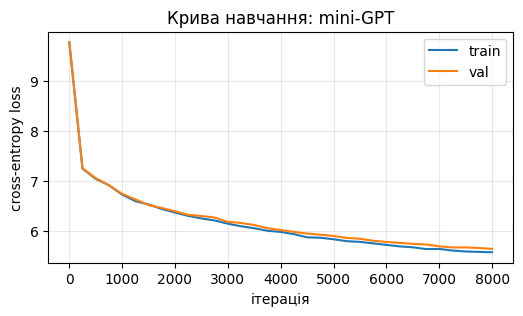


Крива детальніша, можна краще спостерігати локальні коливання втрат.


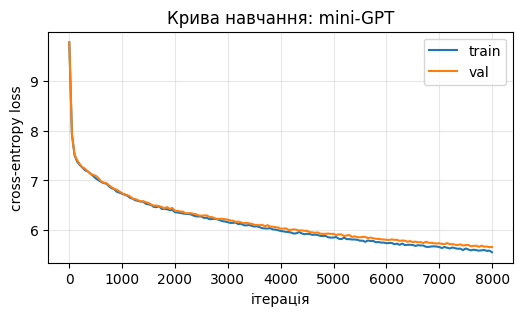

Зменшення `EVAL_INTERVAL` з 250 до 50 зробило криву навчання інформативнішою, проте збільшило час виконання на 3.7 хв (приблизно 58%) через частіші виклики `estimate_loss()`. Кінцеві значення втрат практично не змінилися. Тому подальше зменшення інтервалу недоцільне, якщо немає потреби в детальнішому моніторингу навчання.


11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.

Параметр `temperature` змінює розподіл ймовірностей наступного токена, шляхом ділення логітів моделі на значення температури перед застосуванням `softmax`:

$$\operatorname{softmax}(y_i) = \frac{e^{\frac{y_i}{T}}}{\sum_{j=1}^{n} e^{\frac{y_j}{T}}}$$

тобто
- \\(0<T<1\\) - різниця між логітами збільшується.
- \\(T=1\\) - логіти не змінюються.
- \\(T>1\\) - різниця між логітами зменшується.
- \\(T\to+\infty\\) - усі ймовірності прямують до \\(1/n\\), де \\(n\\) - кількість можливих токенів.

12. За що саме відповідає параметр `top_p`?

Обмеження набору токенів, з яких модель може вибирати наступний токен, залежно від їхньої сумарної ймовірності.

$$0<\text{top}_p\le1$$

13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

У разі ввімкнення параметра `enable_thinking=True` результати генерації стали більш розгорнутими: модель частіше описувала послідовність дій персонажа, намагалася пояснити походження шуму та поступово розвивала сюжет. За низьких значень `temperature` і `top_p` текст залишався відносно передбачуваним, але містив повтори й логічно незавершені конструкції. За високих значень параметрів генерація була більш різноманітною та творчою, проте в тексті зберігалися мовні помилки й нелогічні образи.

In [ ]:
import sys
import os
import math
import time
import json
import numpy as np

import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import gc

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab3"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)

MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

print("Artifacts are stored in:", ARTIFACT_DIR)

Mounted at /content/drive
Artifacts are stored in: /content/drive/MyDrive/ai_systems/lab3


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

In [ ]:
!wget -q --show-progress -O fiction.txt.bz2 "https://lang.org.ua/static/downloads/ubertext2.0/fiction/cleansed/ubertext.fiction.filter_rus_gcld+short.text_only.txt.bz2"
!bzcat fiction.txt.bz2 | head -c 1500

fiction.txt.bz2     100%[===================>] 413.02M  16.5MB/s    in 27s     
Кінний міліціонер

Це тільки з першого погляду Беймбет Кунанбаєв видасться дикуном і відлюдьком,
але досить придивитись до нього пильніше, спробувати поговорити з ним, як
побачиш, що цей літній казах, якому перейшло вже за п'ятдесят, є добродушна,
але вельми скривджена в житті людина. Так скривджена, що й досі не може
очуматись, дарма що відтоді, як заподіяно йому страшну кривду, минуло вже
чотири роки. Легко сказати — чотири роки, а скільки за цей час випало лиха на
бідолашного Беймбета! Скільки довелось йому зазнати поневірянь, голоду,
холоду, муки, куди тільки не носило його скаламучене житейське море, мов
безвільну тріску, в які сніги й морози не закидало Беймбета! Якби хтось сказав
йому раніш, що все це станеться з ним насправді, а не насниться в гарячковому
страшному сні, — Беймбет не повірив би. А ще ж треба ші

In [ ]:
LIMIT_MB = 100

input_file = "fiction.txt.bz2"
output_file = f"fiction_{LIMIT_MB}mb.txt"

In [ ]:
import bz2

limit_bytes = LIMIT_MB * 1024 * 1024

with bz2.open(input_file, "rb") as src:
  data = src.read(limit_bytes)

text = data.decode("utf-8", errors="ignore")

with open(output_file, "w", encoding="utf-8", newline="\n") as dst:
  dst.write(text)

print(f"Extracted {len(text.encode('utf-8')) / (1024**2):.2f} MiB")

Extracted 100.00 MiB


In [ ]:
import re

with open(output_file, encoding="utf-8") as f:
    raw = f.read()

raw = raw.replace("\r\n", "\n")
docs = re.split(r"\n{3,}", raw)

print("Number of documents:", len(docs))
for d in docs[:3]:
    print(repr(d[:200]), "\n---")

Number of documents: 914
'Кінний міліціонер\n\nЦе тільки з першого погляду Беймбет Кунанбаєв видасться дикуном і відлюдьком,\nале досить придивитись до нього пильніше, спробувати поговорити з ним, як\nпобачиш, що цей літній казах,' 
---
'Автобіографія\n\nВ горах, де ближче сонця, перший раз приглянувся небу,\nтоді щось дивне й незнане пробудилося у мені,\nі піднеслася голова, й слова прийшли до уст зелені.\nТепер — де б я не був і коли-неб' 
---
'Слово матері\n\nЯкби ви знали, паничі...\nТарас Шевченко\n\nЦе оповідання я почув від одного пенсіонера. Як і я, він зайшов ненадовго до\nнашого спільного знайомого, начальника цеху великого київського заво' 
---


In [ ]:
import unicodedata

def unwrap(text):
  lines = [l.strip() for l in text.split('\n')]
  out, cur = [], ''
  for i, l in enumerate(lines):
    if not l:
      if cur: out.append(cur); cur = ''
      continue
    if cur and l.startswith(('—', '–')):
      out.append(cur); cur = l
    elif cur and len(cur) < 60 and cur[-1] in '.!?…»"':
      out.append(cur); cur = l
    else:
      cur = (cur + ' ' + l) if cur else l
  if cur: out.append(cur)
  return '\n'.join(out)

def clean(text):
  text = unicodedata.normalize('NFC', text)
  text = re.sub(r'\[\d+\]', '', text)
  text = text.replace('\u00a0', ' ')
  text = re.sub(r'[ \t]+', ' ', text)
  text = re.sub(r' ([,.;:!?])', r'\1', text)
  text = unwrap(text)
  return text.strip()

cleaned = [clean(d) for d in docs]
cleaned = [d for d in cleaned if len(d) > 500]
cleaned = list(dict.fromkeys(cleaned))

print("Number of documents:", len(cleaned))
for d in cleaned[:3]:
    print(repr(d[:200]), "\n---")

Number of documents: 721
'Кінний міліціонер\nЦе тільки з першого погляду Беймбет Кунанбаєв видасться дикуном і відлюдьком, але досить придивитись до нього пильніше, спробувати поговорити з ним, як побачиш, що цей літній казах, ' 
---
'Слово матері\nЯкби ви знали, паничі...\nТарас Шевченко\nЦе оповідання я почув від одного пенсіонера. Як і я, він зайшов ненадовго до нашого спільного знайомого, начальника цеху великого київського заводу' 
---
'Привітання життя\nІ день і вік однаково минають. Не задержать нам хвилі. Кожна мить знов родить другу мить, і перша в другій спить, обі у третій, та, як вежа, час виростає й меж не має й нас німить. Та' 
---


In [ ]:
text = "\n\n".join(cleaned)

print("Corpus size:", len(text), "characters")
print("First 500 characters of the corpus:\n", text[:500])

Corpus size: 58332775 characters
First 500 characters of the corpus:
 Кінний міліціонер
Це тільки з першого погляду Беймбет Кунанбаєв видасться дикуном і відлюдьком, але досить придивитись до нього пильніше, спробувати поговорити з ним, як побачиш, що цей літній казах, якому перейшло вже за п'ятдесят, є добродушна, але вельми скривджена в житті людина. Так скривджена, що й досі не може очуматись, дарма що відтоді, як заподіяно йому страшну кривду, минуло вже чотири роки. Легко сказати — чотири роки, а скільки за цей час випало лиха на бідолашного Беймбета! Скільки


In [ ]:
words = text.split()
unique_words = set(w.lower() for w in words)

print("Words:        ", len(words))
print("Unuque words: ", len(unique_words))

Words:         9581550
Unuque words:  852462


In [ ]:
df = pd.DataFrame(cleaned, columns=["text"])

In [ ]:
del data, text, raw, docs, cleaned, words, unique_words
gc.collect

<function gc.collect(generation=2)>

---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

In [ ]:
from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, decoders, trainers
from transformers import AutoTokenizer

In [ ]:
VOCAB_SIZE=500
SAMPLE = df['text'].head(5).tolist()

text = "він зайшов ненадовго до нашого спільного знайомого"

### Тренування нового токенізатора на основі старого

In [ ]:
qwen = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
qwen_retrained = qwen.train_new_from_iterator(
  text_iterator=SAMPLE,
  vocab_size=VOCAB_SIZE
)

print("default", qwen.tokenize(text))
print("retrained", qwen_retrained.tokenize(text))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

default ['Ð²', 'Ñĸ', 'Ð½', 'ĠÐ·Ð°Ð¹', 'ÑĪ', 'Ð¾Ð²', 'ĠÐ½', 'ÐµÐ½', 'Ð°Ð´', 'Ð¾Ð²', 'Ð³Ð¾', 'ĠÐ´Ð¾', 'ĠÐ½Ð°ÑĪ', 'Ð¾Ð³Ð¾', 'ĠÑģÐ¿', 'Ñĸ', 'Ð»ÑĮ', 'Ð½Ð¾Ð³Ð¾', 'ĠÐ·Ð½', 'Ð°Ð¹', 'Ð¾Ð¼', 'Ð¾Ð³Ð¾']
retrained ['Ð²', 'ÑĸÐ½', 'ĠÐ·', 'Ð°Ð¹', 'ÑĪ', 'Ð¾Ð²', 'ĠÐ½Ðµ', 'Ð½', 'Ð°Ð´', 'Ð¾Ð²', 'Ð³', 'Ð¾', 'ĠÐ´Ð¾', 'ĠÐ½Ð°', 'ÑĪ', 'Ð¾Ð³Ð¾', 'ĠÑģÐ¿', 'ÑĸÐ»ÑĮ', 'Ð½', 'Ð¾Ð³Ð¾', 'ĠÐ·', 'Ð½', 'Ð°Ð¹', 'Ð¾Ð¼', 'Ð¾Ð³Ð¾']


### Алгоритм BPE

In [ ]:
bpe = Tokenizer(models.BPE())
bpe.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe.decoder = decoders.ByteLevel()
bpe_trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=["<|endoftext|>"],
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
)
bpe.train_from_iterator(SAMPLE, trainer=bpe_trainer)

### Алгоритм WordPiece

In [ ]:
wp = Tokenizer(models.WordPiece(unk_token="[UNK]"))
wp.normalizer = normalizers.Sequence([normalizers.NFC(), normalizers.Lowercase()])
wp.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
wp.decoder = decoders.WordPiece(prefix="##")
wp_trainer = trainers.WordPieceTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=["[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"],
)
wp.train_from_iterator(SAMPLE, trainer=wp_trainer)

### Алгоритм Unigram

In [ ]:
uni = Tokenizer(models.Unigram())
uni.normalizer = normalizers.Sequence([normalizers.NFKC(), normalizers.Lowercase()])
uni.pre_tokenizer = pre_tokenizers.Metaspace()
uni.decoder = decoders.Metaspace()
uni_trainer = trainers.UnigramTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=["<unk>"],
    unk_token="<unk>",
)
uni.train_from_iterator(SAMPLE, trainer=uni_trainer)

### Порівняння

In [ ]:
tokenizers_ = {
  "BPE": bpe,
  "WordPiece": wp,
  "Unigram": uni
}

In [ ]:
for name, tok in tokenizers_.items():
  n = sum(len(e.tokens) for e in tok.encode_batch(SAMPLE))
  print(name,
    "| vocab:", tok.get_vocab_size(),
    "| tokens on sample:", n)

BPE | vocab: 500 | tokens on sample: 47198
WordPiece | vocab: 500 | tokens on sample: 38891
Unigram | vocab: 500 | tokens on sample: 38540


In [ ]:
for name, tok in tokenizers_.items():
  print(name,
    "| tokens on text:", len(tok.encode(text).tokens))

BPE | tokens on text: 24
WordPiece | tokens on text: 20
Unigram | tokens on text: 20


In [ ]:
import re
from collections import Counter

frequency = Counter(w for t in SAMPLE for w in re.findall(r"\w+", t.lower()))
frequent = next(w for w, _ in frequency.most_common() if len(w) >= 5)
rare = min(frequency, key=frequency.get)

print(frequent, frequency[frequent], "|", rare, frequency[rare])

for word in [frequent, rare]:
    print()
    for name, tok in tokenizers_.items():
        print(name, word, "->", tok.encode(word).tokens)

тільки 48 | кінний 1

BPE тільки -> ['ÑĤ', 'ÑĸÐ»ÑĮÐºÐ¸']
WordPiece тільки -> ['тільки']
Unigram тільки -> ['▁тільки']

BPE кінний -> ['Ðº', 'ÑĸÐ½', 'Ð½Ð¸', 'Ð¹']
WordPiece кінний -> ['к', '##ін', '##ний']
Unigram кінний -> ['▁кінн', 'ий']


| Алгоритм  | Розмір словника | Токенів на зразку | Токенів на реченні | Частотне | Рідкісне |
| - | - | - | - | - | - |
| BPE | 500 | 47198 | 24 | 2 | 4 |
| WordPiece | 500 | 38891 | 20 | 1 | 3 |
| Unigram   | 500 | 38540 | 20 | 1 | 2 |

Найкоротші послідовності токенів дали WordPiece та Unigram: на реченні - по 20 токенів проти 24 у BPE, а на всьому зразку - 38891 токен у WordPiece та 38540 в Unigram проти 47198 у BPE. Таким чином, Unigram показав найкращий результат за обома показниками, хоча різниця між ним і WordPiece на рівні речення відсутня.

BPE має найдовші послідовності, що узгоджується з особливостями його реалізації в туторіалі. Алгоритм працює на рівні байтів, тому 256 позицій словника займає базовий байтовий алфавіт, а для злиття залишається лише близько 240. Крім того, символи кирилиці в UTF-8 зазвичай кодуються 2-ма байтами, що впливає на початкове розбиття тексту. WordPiece та Unigram натомість починають із символів, тому за розміру словника 500 мають більше можливостей для представлення підслів.

Для частотного слова WordPiece та Unigram сформували по одному токену, тоді як BPE розбив його на 4 частини. На рідкісному слові всі 3 алгоритми використали розбиття на підслова, але з різними результатами: WordPiece формує короткі фрагменти з префіксом `##`, обираючи злиття на основі оцінки; BPE обирає найчастіші пари токенів для злиття, а Unigram починає з великого словника та поступово відсіює токени відповідно до зміни втрат.

In [ ]:
del SAMPLE, text, qwen, qwen_retrained, bpe, wp, uni, frequency
gc.collect()

0

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

### Конфігурація

In [ ]:
BASE_CFG = dict(
  VOCAB_SIZE=8000,
  CONTEXT_LEN=64,
  EMBED_DIM=128,
  N_HEADS=4,
  N_LAYERS=4,
  DROPOUT=0.1,
  BATCH_SIZE=64,
  LEARNING_RATE=3e-4,
  MAX_ITERS=12000,
  EVAL_INTERVAL=250,
  EVAL_ITERS=50,
)

ARCH_KEYS = ("VOCAB_SIZE", "EMBED_DIM", "N_HEADS", "N_LAYERS", "CONTEXT_LEN")

EXPERIMENTS = {
  "minigpt_v1": dict(BASE_CFG),
  "minigpt_v1_vb4k": dict(BASE_CFG, VOCAB_SIZE=4000),
  "minigpt_v1_ctx128": dict(BASE_CFG, CONTEXT_LEN=128),
  "minigpt_v1_e256": dict(BASE_CFG, EMBED_DIM=256),
  "minigpt_v1_H8": dict(BASE_CFG, N_HEADS=8),
  "minigpt_v1_L8": dict(BASE_CFG, N_LAYERS=8),
}

for cfg in EXPERIMENTS.values():
  assert cfg["EMBED_DIM"] % cfg["N_HEADS"] == 0, "EMBED_DIM must be divisible by N_HEADS"

### Токенізація

In [ ]:
def tokenizer_path(vocab_size: int) -> str:
  return os.path.join(ARTIFACT_DIR, f"bpe_v{vocab_size}.json")

def train_tokenizer(texts, vocab_size: int) -> Tokenizer:
  tok = Tokenizer(models.BPE(unk_token="<unk>"))
  tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
  tok.decoder = decoders.ByteLevel()
  trainer = trainers.BpeTrainer(
      vocab_size=vocab_size,
      special_tokens=["<unk>", "<eos>"],
      initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
  )
  tok.train_from_iterator(texts, trainer=trainer)
  return tok

def get_tokenizer(vocab_size: int, df=None, force_retrain=False) -> Tokenizer:
  path = tokenizer_path(vocab_size)
  if os.path.exists(path) and not force_retrain:
    print(f"[tokenizer] loaded {path}")
    return Tokenizer.from_file(path)
  assert df is not None, f"No tokenizer on disk for vocab {vocab_size}, need df to train one"
  print(f"[tokenizer] training vocab_size={vocab_size}")
  texts = df["text"].dropna().tolist()
  tok = train_tokenizer(texts, vocab_size)
  del texts; gc.collect()
  tok.save(path)
  print(f"[tokenizer] saved {path}")
  return tok

### Кодування корпусу

In [ ]:
ENCODE_BATCH_SIZE = 1000

def encode_corpus(tok: Tokenizer, df) -> np.ndarray:
    eos_id = tok.token_to_id("<eos>")
    texts = df["text"].dropna().tolist()
    chunks = []
    for start in range(0, len(texts), ENCODE_BATCH_SIZE):
        for enc in tok.encode_batch(texts[start:start + ENCODE_BATCH_SIZE]):
            chunks.append(np.array(enc.ids + [eos_id], dtype=np.int32))
    del texts; gc.collect()
    ids = np.concatenate(chunks)
    del chunks; gc.collect()
    return ids

def get_corpus_ids(vocab_size: int, tok: Tokenizer, df=None) -> np.ndarray:
    path = os.path.join(ARTIFACT_DIR, f"tokens_v{vocab_size}.npy")
    if os.path.exists(path):
        print(f"[data] loaded {path}")
        return np.load(path)
    assert df is not None, f"No encoded corpus for vocab {vocab_size}, need df"
    ids = encode_corpus(tok, df)
    np.save(path, ids)
    print(f"[data] saved {path}")
    return ids

### Код класів моделі

In [ ]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        causal_mask = torch.tril(torch.ones(context_len, context_len))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)   # (B, T, head_dim)
        k = self.key(x)     # (B, T, head_dim)
        v = self.value(x)   # (B, T, head_dim)

        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])   # (B, T, T)
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = nn.functional.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ v   # (B, T, head_dim)

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))

In [ ]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x

In [ ]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int, context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)                                   # (B, T, C)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))  # (T, C)
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)   # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = nn.functional.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0, top_k: int | None = None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = nn.functional.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx

### Тренування

In [ ]:
from torch.utils.tensorboard import SummaryWriter

def make_get_batch(train_data, val_data, cfg):
    def get_batch(split: str):
        source = train_data if split == "train" else val_data
        ctx = cfg["CONTEXT_LEN"]
        ix = torch.randint(len(source) - ctx - 1, (cfg["BATCH_SIZE"],))
        x = torch.stack([source[i:i + ctx] for i in ix])
        y = torch.stack([source[i + 1:i + ctx + 1] for i in ix])
        return x.to(device), y.to(device)
    return get_batch

@torch.no_grad()
def estimate_loss(model, get_batch, eval_iters):
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(eval_iters)
        for i in range(eval_iters):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

def load_data(cfg: dict, df=None):
    tok = get_tokenizer(cfg["VOCAB_SIZE"], df)
    vocab_size = tok.get_vocab_size()
    ids = get_corpus_ids(cfg["VOCAB_SIZE"], tok, df)
    unk_share = float((ids == tok.token_to_id("<unk>")).mean())
    print(f"tokens: {len(ids):,}  <unk>: {unk_share:.2%}  vocab: {vocab_size}")

    data = torch.from_numpy(ids.astype(np.int64))
    split_idx = int(len(data) * 0.9)
    return tok, vocab_size, data[:split_idx], data[split_idx:], unk_share


def _atomic_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def run_experiment(name: str, cfg: dict, df=None, seed: int = 42):
    print(f"\n===== {name} =====\n{cfg}")

    # --- output locations ---
    best_path = os.path.join(MODELS_DIR, f"{name}.pt")
    last_path = os.path.join(MODELS_DIR, f"{name}_last.pt")
    run_dir = os.path.join(RUNS_DIR, name)
    os.makedirs(run_dir, exist_ok=True)
    config_path = os.path.join(run_dir, "config.json")
    results_path = os.path.join(run_dir, "results.json")

    # --- try to resume ---
    resume = None
    if os.path.exists(last_path):
        resume = torch.load(last_path, map_location=device, weights_only=False)
        bad = [k for k in ARCH_KEYS if resume["cfg"].get(k) != cfg.get(k)]
        if bad:
            raise ValueError(f"Checkpoint for '{name}' has different architecture params {bad}; "
                             f"use a new experiment name or delete old checkpoints.")
        if resume["next_it"] >= cfg["MAX_ITERS"]:
            print(f"Already trained to iter {resume['next_it']} >= MAX_ITERS={cfg['MAX_ITERS']}, skipping.")
            with open(results_path) as f:
                return json.load(f)
        print(f"Resuming from iter {resume['next_it']}")

    start_it = resume["next_it"] if resume else 0

    torch.manual_seed(seed + start_it)

    # --- data ---
    tok, vocab_size, train_data, val_data, unk_share = load_data(cfg, df)
    get_batch = make_get_batch(train_data, val_data, cfg)

    # --- model / optimizer ---
    model = MiniGPT(
        vocab_size=vocab_size,
        embed_dim=cfg["EMBED_DIM"],
        n_heads=cfg["N_HEADS"],
        n_layers=cfg["N_LAYERS"],
        context_len=cfg["CONTEXT_LEN"],
        dropout=cfg["DROPOUT"],
    ).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"params: {n_params:,}")

    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["LEARNING_RATE"])

    if resume is not None:
        model.load_state_dict(resume["model"])
        optimizer.load_state_dict(resume["optimizer"])
        train_losses = resume["train_losses"]
        val_losses = resume["val_losses"]
        checkpoint_iters = resume["iters"]
        best_val_loss = resume["best_val_loss"]
        best_iter = resume["best_iter"]
        prev_elapsed = resume["elapsed"]
    else:
        train_losses, val_losses, checkpoint_iters = [], [], []
        best_val_loss, best_iter = float("inf"), None
        prev_elapsed = 0.0

    with open(config_path, "w") as f:
        json.dump(dict(cfg, ACTUAL_VOCAB_SIZE=vocab_size, N_PARAMS=n_params), f, indent=2)

    writer = SummaryWriter(run_dir)
    start_time = time.time()

    def elapsed_total():
        return prev_elapsed + (time.time() - start_time)

    for it in range(start_it, cfg["MAX_ITERS"]):
        xb, yb = get_batch("train")
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if it % cfg["EVAL_INTERVAL"] == 0 or it == cfg["MAX_ITERS"] - 1:
            losses = estimate_loss(model, get_batch, cfg["EVAL_ITERS"])
            train_losses.append(losses["train"])
            val_losses.append(losses["val"])
            checkpoint_iters.append(it)
            writer.add_scalar("Loss/train", losses["train"], it)
            writer.add_scalar("Loss/val", losses["val"], it)

            print(f"iter {it:5d}  train_loss={losses['train']:.3f}  "
                  f"val_loss={losses['val']:.3f}  ({elapsed_total() / 60:.1f} min)")

            if losses["val"] < best_val_loss:
                best_val_loss, best_iter = losses["val"], it
                _atomic_save({"model": model.state_dict(), "cfg": cfg,
                              "vocab_size": vocab_size, "iter": it,
                              "val_loss": best_val_loss}, best_path)

            # resume state
            _atomic_save({"model": model.state_dict(),
                          "optimizer": optimizer.state_dict(),
                          "cfg": cfg, "vocab_size": vocab_size,
                          "next_it": it + 1,
                          "train_losses": train_losses, "val_losses": val_losses,
                          "iters": checkpoint_iters,
                          "best_val_loss": best_val_loss, "best_iter": best_iter,
                          "elapsed": elapsed_total()}, last_path)

    writer.close()
    print(f"Done in {elapsed_total() / 60:.1f} min total"
          f"Best: iter {best_iter} (val_loss={best_val_loss:.3f})")

    result = dict(name=name, best_val_loss=best_val_loss, best_iter=best_iter,
                  n_params=n_params, unk_share=unk_share,
                  train_losses=train_losses, val_losses=val_losses,
                  iters=checkpoint_iters)
    with open(results_path, "w") as f:
        json.dump(result, f, indent=2)
    del model, optimizer, train_data, val_data
    gc.collect(); torch.cuda.empty_cache()
    return result

In [ ]:
results = {n: run_experiment(n, c, df=df) for n, c in EXPERIMENTS.items()}


===== minigpt_v1 =====
{'VOCAB_SIZE': 8000, 'CONTEXT_LEN': 64, 'EMBED_DIM': 128, 'N_HEADS': 4, 'N_LAYERS': 4, 'DROPOUT': 0.1, 'BATCH_SIZE': 64, 'LEARNING_RATE': 0.0003, 'MAX_ITERS': 12000, 'EVAL_INTERVAL': 250, 'EVAL_ITERS': 50}
Already trained to iter 12000 >= MAX_ITERS=12000, skipping.

===== minigpt_v1_vb4k =====
{'VOCAB_SIZE': 4000, 'CONTEXT_LEN': 64, 'EMBED_DIM': 128, 'N_HEADS': 4, 'N_LAYERS': 4, 'DROPOUT': 0.1, 'BATCH_SIZE': 64, 'LEARNING_RATE': 0.0003, 'MAX_ITERS': 12000, 'EVAL_INTERVAL': 250, 'EVAL_ITERS': 50}
Already trained to iter 12000 >= MAX_ITERS=12000, skipping.

===== minigpt_v1_ctx128 =====
{'VOCAB_SIZE': 8000, 'CONTEXT_LEN': 128, 'EMBED_DIM': 128, 'N_HEADS': 4, 'N_LAYERS': 4, 'DROPOUT': 0.1, 'BATCH_SIZE': 64, 'LEARNING_RATE': 0.0003, 'MAX_ITERS': 12000, 'EVAL_INTERVAL': 250, 'EVAL_ITERS': 50}
Already trained to iter 12000 >= MAX_ITERS=12000, skipping.

===== minigpt_v1_e256 =====
{'VOCAB_SIZE': 8000, 'CONTEXT_LEN': 64, 'EMBED_DIM': 256, 'N_HEADS': 4, 'N_LAYERS': 4, '

### Тестування

In [ ]:
def load_experiment(name: str):
    ckpt = torch.load(os.path.join(MODELS_DIR, f"{name}.pt"), map_location=device)
    cfg = ckpt["cfg"]
    tok = Tokenizer.from_file(tokenizer_path(cfg["VOCAB_SIZE"]))
    model = MiniGPT(vocab_size=ckpt["vocab_size"], embed_dim=cfg["EMBED_DIM"],
                    n_heads=cfg["N_HEADS"], n_layers=cfg["N_LAYERS"],
                    context_len=cfg["CONTEXT_LEN"], dropout=cfg["DROPOUT"]).to(device)
    model.load_state_dict(ckpt["model"])
    model.eval()
    return model, tok, cfg

@torch.no_grad()
def generate_from(model, tok, cfg, prompt, max_new_tokens=60, temperature=0.8, top_k=40, seed=42):
    torch.manual_seed(seed)
    ids = tok.encode(prompt).ids
    x = torch.tensor([ids], dtype=torch.long, device=device)
    out = model.generate(x, max_new_tokens, temperature=temperature, top_k=top_k)
    return tok.decode(out[0].tolist())

In [ ]:
PROMPT = "— Що ти накоїв"
names = EXPERIMENTS.keys()

results = {}
for name in names:
    model, tok, cfg = load_experiment(name)
    results[name] = generate_from(model, tok, cfg, PROMPT, max_new_tokens=60)
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()

for name, text in results.items():
    print(f"=== {name} ===")
    print(text, "\n")

=== minigpt_v1 ===
— Що ти накоїв?
— Ні, як ти, — сказав він. — І я нічого не відколи, а хто мені не те, що ж, — з них тобі від того, як і ще й не до вас, — говорив він, — він знову почав. — То так, що це я 

=== minigpt_v1_vb4k ===
— Що ти накоїв?
— Що ж вона.
— Як ти хочеш?
— Снива?
— Не знаю! — крикнув він.— А ми з вами!
— Ну, що ж, — обозринувши, що жде! Яківка по-натому й пере 

=== minigpt_v1_ctx128 ===
— Що ти накоїв?
— Ні, ні.
— Як ти хочеш.
— Що це?
— Учора ввечері?
Возор, а з них подивився на стіл.
— Ну, — питає, — показав той бік, — він знову озвався старий.
— Тягай, 

=== minigpt_v1_e256 ===
— Що ти накоїваєш?
— То як ти, Мар'ю, то я...
Вона дивилася на нього і не думала, що я — не знаю, що ти такий, може, як і не знаю, й за те, що він і не може жити. Це його знає, чим воно так, 

=== minigpt_v1_H8 ===
— Що ти накоїв?
— Ні, як ти, — сказав він. — І я не знаю. Бо що ти тут? А що? — запитав я, що ти такий, може бути?
— А що й за твоє?
— Я знаю, що ти так би до вас.
— Хто 

==

In [ ]:
import os, json, math
import pandas as pd

COLUMNS = {
    "model": "Model Name",
    "n_params": "Number of Parameters",
    "layers": "Number of Layers",
    "embed_dim": "Embedding Dimension",
    "heads": "Number of Attention Heads",
    "context_len": "Context Length",
    "vocab_size": "Vocabulary Size",
    "best_iter": "Best Iteration",
    "best_val_loss": "Best Validation Loss",
    "train_loss_at_best": "Training Loss at Best Iteration",
    "gap_val_minus_train": "Validation Minus Training Loss",
    "final_val_loss": "Final Validation Loss",
    "unk_share": "Unknown Token Share",
}

def build_results_table():
    rows = []
    for name in sorted(os.listdir(RUNS_DIR)):
        run_dir = os.path.join(RUNS_DIR, name)
        res_path = os.path.join(run_dir, "results.json")
        cfg_path = os.path.join(run_dir, "config.json")
        if not os.path.isfile(res_path):
            print(f"skip '{name}': no results.json (unfinished run?)")
            continue

        with open(res_path) as f:
            res = json.load(f)
        cfg = {}
        if os.path.isfile(cfg_path):
            with open(cfg_path) as f:
                cfg = json.load(f)

        iters, tr, va = res["iters"], res["train_losses"], res["val_losses"]
        best_val = res["best_val_loss"]
        best_idx = iters.index(res["best_iter"]) if res["best_iter"] in iters else -1

        rows.append({
            "model": res["name"],
            "n_params": res["n_params"],
            "layers": cfg.get("N_LAYERS"),
            "embed_dim": cfg.get("EMBED_DIM"),
            "heads": cfg.get("N_HEADS"),
            "context_len": cfg.get("CONTEXT_LEN"),
            "vocab_size": cfg.get("ACTUAL_VOCAB_SIZE"),
            "best_iter": res["best_iter"],
            "best_val_loss": best_val,
            "train_loss_at_best": tr[best_idx],
            "gap_val_minus_train": best_val - tr[best_idx],
            "final_val_loss": va[-1],
            "unk_share": res.get("unk_share"),
        })

    df = pd.DataFrame(rows).sort_values("best_val_loss").reset_index(drop=True)
    return df.rename(columns=COLUMNS)

df = build_results_table()

os.makedirs(ARTIFACT_DIR, exist_ok=True)
csv_path = os.path.join(ARTIFACT_DIR, "results.csv")
df.to_csv(csv_path, index=False)
print(f"saved -> {csv_path}")

display(
    df.style.format({
        "Number of Parameters": "{:,}",
        "Best Validation Loss": "{:.4f}",
        "Validation Perplexity": "{:.2f}",
        "Training Loss at Best Iteration": "{:.4f}",
        "Validation Minus Training Loss": "{:+.4f}",
        "Final Validation Loss": "{:.4f}",
        "Unknown Token Share": "{:.2%}",
    })
)

saved -> /content/drive/MyDrive/ai_systems/lab3/results.csv


,Model Name,Number of Parameters,Number of Layers,Embedding Dimension,Number of Attention Heads,Context Length,Vocabulary Size,Best Iteration,Best Validation Loss,Training Loss at Best Iteration,Validation Minus Training Loss,Final Validation Loss,Unknown Token Share
0,minigpt_v1_vb4k,"1,828,000",4,128,4,64,4000,11999,4.8165,4.6647,+0.1518,4.8165,0.00%
1,minigpt_v1_e256,"7,276,864",4,256,4,64,8000,11999,4.9315,4.6705,+0.2610,4.9315,0.00%
2,minigpt_v1_L8,"3,647,552",8,128,4,64,8000,11999,5.1540,4.9456,+0.2084,5.1540,0.00%
3,minigpt_v1_ctx128,"2,864,192",4,128,4,128,8000,11750,5.2322,5.0623,+0.1699,5.2324,0.00%
4,minigpt_v1_H8,"2,856,000",4,128,8,64,8000,11999,5.2582,5.0895,+0.1687,5.2582,0.00%
5,minigpt_v1,"2,856,000",4,128,4,64,8000,11999,5.2702,5.0928,+0.1774,5.2702,0.00%


Найкращий val_loss (4.82) показав варіант зі словником 4000, за ним йшов варіант з EMBED_DIM=256 (4.93); базова модель була найгіршою (5.27). Найбільший ефект дали зміна словника та ширина моделі, тоді як кількість голів і довжина контексту майже не вплинули. За якістю тексту різниця помітна слабо: усі моделі видають граматично схожу, але беззмістовну прозу, а лише e256 трохи частіше тримає зв'язні фрази. Порівняння vb4k з іншими не повністю чесне, бо loss на токен залежить від розміру словника.

In [ ]:
names = EXPERIMENTS.keys()

logdir_spec = ",".join(
    f"{name}:{os.path.join(RUNS_DIR, name)}"
    for name in names
)

%load_ext tensorboard
%tensorboard --logdir_spec $logdir_spec

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

In [ ]:
del df
gc.collect()

if torch.cuda.is_available():
  torch.cuda.empty_cache()

### 4.0. Запустіть приклади виконання різних NLP задач

In [ ]:
!pip install "transformers[sentencepiece]==5.18.0"

#### Sentiment analysis

In [ ]:
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


#### Zero-shot classification

In [ ]:
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

#### Text generation

In [ ]:
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to use a Raspberry Pi. This course is also a great tutorial on how to install and install your Raspberry Pi.\n\n\n\n\nThis course is a great tutorial on how to install and install your Raspberry Pi. This course is also a great tutorial on how to install and install your Raspberry Pi. The following information can be found in this course. The instructions are very helpful, but not as helpful as they might be.\nInstalling the Raspberry Pi\nThe Raspberry Pi is a computer that has the necessary hardware and software to use it. However, it is a very simple and easy to build and install. It is also a very easy to use software to build and install your Raspberry Pi.\nThe Raspberry Pi is a computer that has the necessary hardware and software to use it. However, it is a very simple and easy to build and install. It is also a very easy to build and install. It is also a very easy to build and install. It is also a very easy to build and

#### Fill-mask

In [ ]:
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

#### Named entity recognition

In [ ]:
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

#### Question answering

In [ ]:
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

...

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

#### Sentiment analysis

In [ ]:
from transformers import pipeline

classifier = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
)
print(classifier("Я чекав на цей курс з Hugging Face все своє життя!"))
print(classifier([
    "Фільм був неймовірний, дивився б ще раз!",
    "Обслуговування жахливе, більше сюди не прийду.",
    "Звичайний день, нічого особливого.",
]))

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

[{'label': 'positive', 'score': 0.5820118188858032}]
[{'label': 'positive', 'score': 0.9011892080307007}, {'label': 'negative', 'score': 0.9291313886642456}, {'label': 'positive', 'score': 0.4982534945011139}]


#### Zero-shot classification

In [ ]:
from transformers import pipeline

classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
)
classifier(
    "Збірна України з футболу перемогла у відбірковому матчі з рахунком 2:0",
    candidate_labels=["спорт", "політика", "економіка", "освіта"],
    hypothesis_template="Цей текст про {}.",
)

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

{'sequence': 'Збірна України з футболу перемогла у відбірковому матчі з рахунком 2:0',
 'labels': ['спорт', 'освіта', 'політика', 'економіка'],
 'scores': [0.9898614883422852,
  0.0077482531778514385,
  0.0017501026159152389,
  0.0006400653510354459]}

#### Text generation

In [ ]:
from transformers import pipeline

generator = pipeline("text-generation", model="malteos/gpt2-uk")
print(generator("Київ — це місто, де", max_length=40, num_return_sequences=1))

print(generator(
    "На цьому курсі ми навчимо вас, як",
    max_length=30,
    num_return_sequences=2,
    do_sample=True,
))

config.json:   0%|          | 0.00/958 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  511MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: malteos/gpt2-uk
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/344 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=40) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'Київ — це місто, де народжуються, щоб жити. Тут живуть, щоб жити, щоб жити. Тут живуть, щоб жити, щоб жити. Тут живуть, щоб жити, щоб жити, щоб жити. Тут живуть, щоб жити, щоб жити, щоб жити. Тут живуть, щоб жити, щоб жити, щоб жити. Тут живуть, щоб жити, щоб жити, щоб жити, щоб жити, щоб жити, щоб жити.\nПослання апостола Павла до Коринтян\n1. Послання до Коринтян – це послання до Коринтян, яке є перекладом Нового Завіту до Нового Завіту, в якому говориться: “Послухай, що говорять вони до вас, і не бійся бути з ними, бо вони не знають, що вони роблять, і що вони роблять. Вони знають, що вони говорять, як роблять, бо вони знають, що вони роблять” (Лк. 3:14); “Послухай, що говорять вони до вас, і не бійся бути з ними” (Лк. 3:19).\n2. Послання до Коринтян – це послання до Коринтян, яке є перекладом Нового Завіту до Нового Завіту, в якому говориться: “Послухай, що говорять вони до вас, і не бійся бути з ними, бо'}]
[{'generated_text': 'На цьому курсі ми навчимо вас, я

#### Fill-mask

In [ ]:
from transformers import pipeline

unmasker = pipeline("fill-mask", model="xlm-roberta-base")
unmasker("Столиця України — місто <mask>.", top_k=3)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[{'score': 0.28910890221595764,
  'token': 27852,
  'token_str': 'Київ',
  'sequence': 'Столиця України — місто Київ .'},
 {'score': 0.2745856046676636,
  'token': 57968,
  'token_str': 'Львів',
  'sequence': 'Столиця України — місто Львів .'},
 {'score': 0.04267847537994385,
  'token': 82022,
  'token_str': 'Києва',
  'sequence': 'Столиця України — місто Києва .'}]

#### Named entity recognition

In [ ]:
from transformers import pipeline

ner = pipeline(
    "ner",
    model="Babelscape/wikineural-multilingual-ner",
    aggregation_strategy="simple",
)
ner("Генеральний директор компанії Apple Тім Кук відвідав Париж у понеділок, щоб зустрітися з представниками Європейського Союзу.")

config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  709MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/333 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[{'entity_group': 'ORG',
  'score': np.float32(0.9967277),
  'word': 'Apple',
  'start': 30,
  'end': 35},
 {'entity_group': 'PER',
  'score': np.float32(0.92693037),
  'word': 'Тім Кук',
  'start': 36,
  'end': 43},
 {'entity_group': 'LOC',
  'score': np.float32(0.9990644),
  'word': 'Париж',
  'start': 53,
  'end': 58},
 {'entity_group': 'ORG',
  'score': np.float32(0.98036003),
  'word': 'Європейського Союзу',
  'start': 104,
  'end': 123}]

#### Question answering

In [ ]:
from transformers import pipeline

question_answerer = pipeline("table-question-answering")

question_answerer(
    query="Яке місто має найбільше населення?",
    table={
        "Місто": ["Київ", "Львів", "Одеса", "Харків"],
        "Населення (млн)": ["2.95", "0.72", "1.01", "1.42"],
        "Область": ["Київська", "Львівська", "Одеська", "Харківська"],
        "Відоме місце": ["Софійський собор", "Площа Ринок", "Потьомкінські сходи", "Держпром"]
    }
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

{'answer': 'Київ',
 'coordinates': [(0, 0)],
 'cells': ['Київ'],
 'aggregator': 'NONE'}

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [ ]:
!pip install -q transformers evaluate scikit-learn pandas torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.1 MB/s eta 0:00:00


In [ ]:
import time
import evaluate
import pandas as pd
from transformers import pipeline

data = [
    ("Цей фільм просто неймовірний, рекомендую всім!", 1),
    ("Дуже смачна їжа та привітний персонал.", 1),
    ("Я в захваті від нового телефона, камера чудова.", 1),
    ("Курс був корисним, я багато чого навчився.", 1),
    ("Чудова погода, гарний настрій, все вдалося!", 1),
    ("Доставили вчасно, товар навіть кращий, ніж на фото.", 1),
    ("Готель розташований ідеально, номер чистий і затишний.", 1),
    ("Нарешті книжка, яку не хочеться відкладати.", 1),
    ("Підтримка відповіла за п'ять хвилин і розв'язала проблему.", 1),
    ("Не очікував, що буде настільки добре, дякую команді!", 1),

    ("Жахливий сервіс, більше сюди ні ногою.", 0),
    ("Їжа була холодна, а офіціант грубіянив.", 0),
    ("Телефон зламався вже за тиждень, повна розчарування.", 0),
    ("Лекція була нудною, я ледве дочекався кінця.", 0),
    ("Потяг запізнився на три години, ніхто нічого не пояснив.", 0),
    ("Товар прийшов зламаним, а гроші не повертають.", 0),
    ("У номері бруд і шум усю ніч, відпочинок зіпсовано.", 0),
    ("Це найгірший фільм, який я бачив за останні роки.", 0),
    ("Програма постійно вилітає, користуватися неможливо.", 0),
    ("Не рекомендую, даремно витрачені гроші.", 0),
]
texts = [t for t, _ in data]
labels = [y for _, y in data]
print(len(texts), "examples,", sum(labels), "positive")

20 examples, 10 positive


### Допоміжні функції

Уніфікуємо мітки різних моделей до бінарної (pos / neg)

In [ ]:
accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")

def p_positive(scores: list[dict]) -> float:
    s = {d["label"].lower(): d["score"] for d in scores}

    if any("star" in k for k in s):
        neg = s.get("1 star", 0) + s.get("2 stars", 0)
        pos = s.get("4 stars", 0) + s.get("5 stars", 0)
    else:
        fallback = {"label_0": "negative", "label_1": "neutral", "label_2": "positive"}
        s = {fallback.get(k, k): v for k, v in s.items()}
        pos = sum(v for k, v in s.items() if "pos" in k)
        neg = sum(v for k, v in s.items() if "neg" in k)
    return pos / (pos + neg + 1e-9)

def run(pipe, texts, max_length=128, batch_size=8, lowercase=False):
    inp = [t.lower() for t in texts] if lowercase else texts
    kw = dict(top_k=None, truncation=True, max_length=max_length, batch_size=batch_size)
    pipe(inp[:2], **kw)
    start = time.perf_counter()
    out = pipe(inp, **kw)
    ms = (time.perf_counter() - start) / len(inp) * 1000
    return [p_positive(o) for o in out], ms

def score(probs, labels, threshold=0.5):
    preds = [int(p >= threshold) for p in probs]
    return (
        accuracy.compute(predictions=preds, references=labels)["accuracy"],
        f1.compute(predictions=preds, references=labels)["f1"],
    )

def n_params_m(pipe):
    return sum(p.numel() for p in pipe.model.parameters()) / 1e6

### Порівняння моделей на однакових прикладах

In [ ]:
models = {
    "xlm-roberta-base (cardiffnlp)": "cardiffnlp/twitter-xlm-roberta-base-sentiment",
    "distilbert-multilingual (lxyuan)": "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    "bert-multilingual (nlptown)": "nlptown/bert-base-multilingual-uncased-sentiment",
}

pipes, all_probs, rows = {}, {}, []
for name, model_id in models.items():
    pipes[name] = pipeline("text-classification", model=model_id)
    probs, ms = run(pipes[name], texts)
    acc, f = score(probs, labels)
    all_probs[name] = probs
    rows.append({
        "Model": name,
        "Params, M": round(n_params_m(pipes[name]), 1),
        "ms/sentence": round(ms, 1),
        "Accuracy": round(acc, 3),
        "F1": round(f, 3),
    })

results = pd.DataFrame(rows).sort_values("F1", ascending=False)
display(results)
best_name = results.iloc[0]["Model"]
print("Best F1:", best_name)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

,Model,"Params, M",ms/sentence,Accuracy,F1
0,xlm-roberta-base (cardiffnlp),278.0,4.4,0.95,0.952
2,bert-multilingual (nlptown),167.4,8.3,0.85,0.842
1,distilbert-multilingual (lxyuan),135.3,5.1,0.75,0.706


Best F1: xlm-roberta-base (cardiffnlp)


Найкращий результат показала модель xlm-roberta-base з `Accuracy = 0.95` та `F1 = 0.952`. Вона також продемонструвала найвищу швидкість інференсу - 4.4 мс на речення. Кількість її параметрів становить 278 млн, що більше, ніж в інших розглянутих моделей. Модель bert-multilingual має 167.4 млн параметрів, `Accuracy = 0.85` та `F1 = 0.842`, а distilbert-multilingual - 135.3 млн параметрів, `Accuracy = 0.75` та `F1 = 0.706`.

Отже, xlm-roberta-base є найкращою за точністю та F1-мірою, попри більший розмір, а також має найшвидший інференс серед порівнюваних моделей.

### Експерименти з налаштуваннями на найкращій моделі

In [ ]:
best = pipes[best_name]
base = dict(max_length=128, batch_size=8, lowercase=False, threshold=0.5)

experiments = [
    ("baseline", {}),
    ("max_length=8", {"max_length": 8}),
    ("threshold 0.3", {"threshold": 0.3}),
    ("threshold 0.7", {"threshold": 0.7}),
    ("lowercase=True", {"lowercase": True}),
    ("batch_size=1", {"batch_size": 1}),
]

rows = []
for title, change in experiments:
    cfg = {**base, **change}
    probs, ms = run(best, texts, cfg["max_length"], cfg["batch_size"], cfg["lowercase"])
    acc, f = score(probs, labels, cfg["threshold"])
    rows.append({
        "Model": best_name,
        "Change": title,
        "Accuracy": round(acc, 3),
        "F1": round(f, 3),
        "ms/sentence": round(ms, 1),
    })

exp_table = pd.DataFrame(rows)
display(exp_table)

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,Model,Change,Accuracy,F1,ms/sentence
0,xlm-roberta-base (cardiffnlp),baseline,0.95,0.952,7.6
1,xlm-roberta-base (cardiffnlp),max_length=8,0.90,0.900,7.0
2,xlm-roberta-base (cardiffnlp),threshold 0.3,0.95,0.952,10.5
3,xlm-roberta-base (cardiffnlp),threshold 0.7,0.90,0.900,3.2
4,xlm-roberta-base (cardiffnlp),lowercase=True,0.95,0.952,7.0
5,xlm-roberta-base (cardiffnlp),batch_size=1,0.95,0.952,22.8


Найкращі значення `Accuracy = 0.95` та `F1 = 0.952` зберігаються за базових налаштувань, `threshold = 0.3` та `lowercase=True`. Зміна `max_length` до `8` і підвищення порога впевненості до `0.7` призвели до зниження Accuracy до `0.9` та `F1` до `0.9`. Найшвидший інференс серед експериментів зафіксовано при `threshold = 0.7` - 3.2 мс на речення, тоді як `batch_size=1` збільшив час до 22.8 мс.

Таким чином, найкращим вибором за F1-мірою є базова конфігурація моделі, оскільки вона має максимальну якість без погіршення точності. Водночас вплив налаштувань на метрики виявився помірним: зниження F1 становило `0.052`. Це менше за різницю між найкращою та найгіршою моделями в першому експерименті, яка дорівнює `0.246`.

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [1]:
!pip install -q gradio transformers torch matplotlib pandas numpy

In [2]:
import re
from collections import Counter, defaultdict

import gradio as gr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import pipeline

sentiment = pipeline(
    "text-classification",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
    top_k=None,
)
ner = pipeline(
    "ner",
    model="Babelscape/wikineural-multilingual-ner",
    aggregation_strategy="simple",
)

EXAMPLE = (
    "Марія з дитинства мріяла відкрити власну пекарню. "
    "Вранці вона прокидалася вдосвіта й з радістю місила тісто. "
    "Запах свіжого хліба наповнював усю вулицю, а сусіди дякували їй усмішками. "
    "Та одного дня Марія отримала лист про закриття пекарні. "
    "Їй було страшно й гірко. "
    "Вона плакала всю ніч і думала, що все втрачено. "
    "Її друг Тарас не залишив її саму в біді. "
    "Він запропонував допомогу і привів добровольців з усього міста. "
    "Разом вони відремонтували приміщення за вихідні. "
    "Люди стояли в черзі, щоб купити перший хліб після відкриття. "
    "Марія вперше за довгий час засміялася від щастя. "
    "Тепер пекарня процвітає, а Марія і Тарас радо зустрічають кожного гостя."
)

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/333 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [3]:
def split_sentences(text: str) -> list[str]:
    parts = re.split(r"(?<=[.!?…])\s+", text.strip())
    return [p.strip() for p in parts if len(p.strip()) > 2]

def valence(scores: list[dict]) -> float:
    s = {d["label"].lower(): d["score"] for d in scores}
    pos = sum(v for k, v in s.items() if k.startswith("pos") or k == "label_2")
    neg = sum(v for k, v in s.items() if k.startswith("neg") or k == "label_0")
    return pos - neg

SHAPES = {
    "hole": ("Людина в ямі", "Усе добре -> біда -> порятунок. Найпопулярніша форма в літературі й кіно."),
    "icarus": ("Ікар", "Зліт, а потім падіння. Історія про гординю, ілюзії або крихке щастя."),
    "cinder": ("Попелюшка", "Від мороку до світла. Загальна траєкторія - угору."),
    "tragedy": ("Трагедія", "Від світлого початку до темного кінця."),
    "flat": ("Рівна стежка", "Емоційний тон майже не змінюється - це радше опис або звіт, ніж сюжет."),
}

def detect_shape(smooth: np.ndarray) -> tuple[str, str]:
    start, mid, end = [float(c.mean()) for c in np.array_split(smooth, 3)]
    if mid < min(start, end) - 0.2:
        return SHAPES["hole"]
    if mid > max(start, end) + 0.2:
        return SHAPES["icarus"]
    if end - start > 0.3:
        return SHAPES["cinder"]
    if start - end > 0.3:
        return SHAPES["tragedy"]
    return SHAPES["flat"]

def find_characters(sentences: list[str], vals: list[float]) -> pd.DataFrame:
    ents = ner(sentences, batch_size=8)
    mentions, forms = defaultdict(list), defaultdict(Counter)
    for sent_vals, sent_ents in zip(vals, ents):
        for e in sent_ents:
            if e["entity_group"] != "PER":
                continue
            name = e["word"].strip()
            key = name.lower()[:5]
            mentions[key].append(sent_vals)
            forms[key][name] += 1
    rows = [
        {
            "Герой": forms[k].most_common(1)[0][0],
            "Згадок": len(v),
            "Середній заряд": round(float(np.mean(v)), 2),
            "Доля": (
                "Позитивна" if np.mean(v) > 0.15
                else "Негативна" if np.mean(v) < -0.15
                else "Нейтральна"
            ),
        }
        for k, v in mentions.items()
        if len(v) >= 2
    ]
    cols = ["Герой", "Згадок", "Середній заряд", "Доля"]
    return pd.DataFrame(rows, columns=cols).sort_values("Згадок", ascending=False) if rows else pd.DataFrame(columns=cols)

def analyze(text: str, window: int):
    sentences = split_sentences(text)
    if len(sentences) < 4:
        raise gr.Error("Потрібно щонайменше 4 речення, щоб побачити динаміку.")

    out = sentiment(sentences, truncation=True, max_length=128, batch_size=8)
    vals = [valence(o) for o in out]
    smooth = pd.Series(vals).rolling(int(window), center=True, min_periods=1).mean().to_numpy()
    x = np.arange(1, len(vals) + 1)

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(x, vals, color=["#4caf50" if v >= 0 else "#e53935" for v in vals], alpha=0.25)
    ax.plot(x, smooth, color="black", lw=3)
    ax.fill_between(x, smooth, 0, where=smooth >= 0, color="#4caf50", alpha=0.3, interpolate=True)
    ax.fill_between(x, smooth, 0, where=smooth < 0, color="#e53935", alpha=0.3, interpolate=True)
    peak, low = int(np.argmax(smooth)), int(np.argmin(smooth))
    ax.scatter([x[peak]], [smooth[peak]], s=120, color="gold", edgecolor="black", zorder=5, label="пік")
    ax.scatter([x[low]], [smooth[low]], s=120, color="navy", edgecolor="white", zorder=5, label="дно")
    ax.axhline(0, color="gray", lw=1)
    ax.set_ylim(-1.05, 1.05)
    ax.set_xlabel("Номер речення")
    ax.set_ylabel("Емоційний заряд (-1 ... +1)")
    ax.set_title("Емоційна кардіограма історії")
    ax.legend(loc="upper right")
    plt.close(fig)

    name, desc = detect_shape(smooth)
    report = (
        f"## {name}\n{desc}\n\n"
        f"**Речень:** {len(sentences)} · **Середній заряд:** {np.mean(vals):+.2f}\n\n"
        f"**Найсвітліше місце** (речення {peak + 1}): _{sentences[int(np.argmax(vals))]}_\n\n"
        f"**Найтемніше місце** (речення {low + 1}): _{sentences[int(np.argmin(vals))]}_"
    )

    sent_df = pd.DataFrame({"№": x, "Речення": sentences, "Заряд": np.round(vals, 2)})
    return fig, report, find_characters(sentences, vals), sent_df

In [4]:
with gr.Blocks(title="Емоційна кардіограма історії") as demo:
    gr.Markdown(
        "# Емоційна кардіограма історії\n"
        "Вставте оповідання, лист чи уривок книги. Побачите, як змінюється настрій тексту, "
        "яку \"форму\" має історія та що відбувається з кожним героєм."
    )
    with gr.Row():
        with gr.Column(scale=1):
            text = gr.Textbox(label="Ваш текст", lines=12, value=EXAMPLE)
            window = gr.Slider(1, 7, value=3, step=2, label="Згладжування кривої (вікно, речень)")
            btn = gr.Button("Показати кардіограму", variant="primary")
        with gr.Column(scale=1):
            plot = gr.Plot(label="Крива настрою")
            report = gr.Markdown()
    chars = gr.Dataframe(label="Герої та їхня емоційна доля", interactive=False)
    sents = gr.Dataframe(label="Заряд кожного речення", interactive=False, wrap=True)

    btn.click(analyze, [text, window], [plot, report, chars, sents])

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://57917fe98f6e4df29b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```